In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def H_1func(N,a):
    return(np.diag(a * N**2))

Den er god nok, den laver en diagonal matrix med elementerne a*N^2.

In [3]:
def H_2func(L,b):
    A=np.zeros((L,L))
    for i in range(L):
        for j in range(L):
            if (i==j+1):
                A[i,j]=b
            if (i==j-1):
                A[i,j]=b
    return(A)

In [4]:
N_max=10
L=2*N_max+1
N=np.linspace(-N_max,N_max,L )
E_c=1
E_j=100
a=4*E_c
b=-1/2*E_j

In [5]:
H1=H_1func(N,a)
H2=H_2func(L,b)
H=H1+H2

In [6]:
E, V=np.linalg.eigh(H)

In [7]:
print(E[:10]) #10 første energier

[-86.11253853 -58.86740299 -32.7177617   -7.74493632  15.945234
  38.214746    58.77118868  77.86479128  91.41941283 113.06109939]


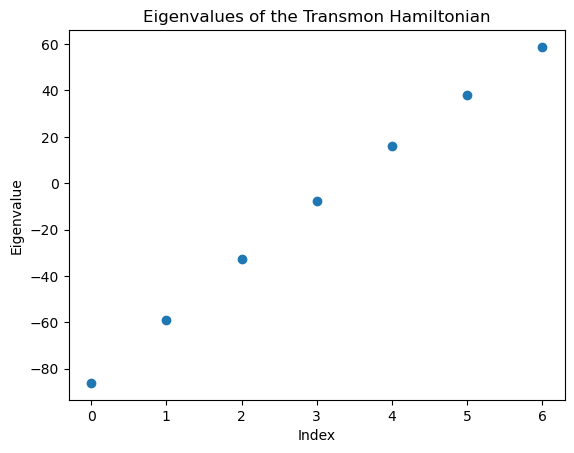

In [8]:
plt.plot(range(7), E[:7],'o')
plt.title('Eigenvalues of the Transmon Hamiltonian')
plt.xlabel('Index')
plt.ylabel('Eigenvalue')
plt.show()

plottet viser at der er degenerering i energiniveauerne så N og -N har samme energi. Dette er forventet da H_1 kun afhænger af N^2. Når E_c er meget større end E_j, vil sandsynligheds funktionerne blive tættere og tættere på hinanden, da det er H_1 der dominerer med N^2. Når E_j bliver større bliver det helt lineært og sandsynligheds funktionerne vil blive mere og mere spredt ud. Dette er fordi H_2 dominerer med sine off-diagonal elementer.

(-5.0, 5.0)

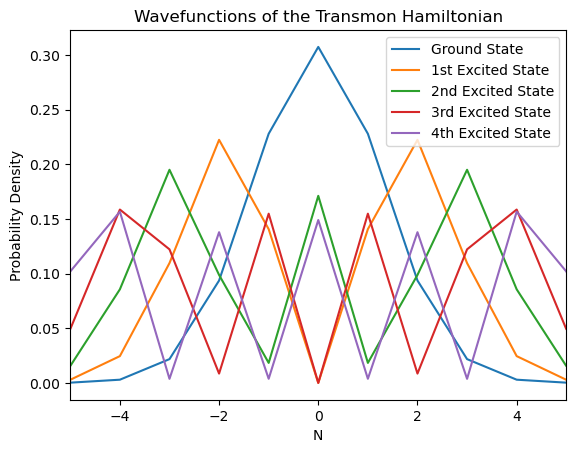

In [9]:
plt.plot(N,(np.abs(V[:,0])**2))
plt.plot(N,(np.abs(V[:,1])**2))
plt.plot(N,(np.abs(V[:,2])**2))
plt.plot(N,(np.abs(V[:,3])**2))
plt.plot(N,(np.abs(V[:,4])**2))
plt.title('Wavefunctions of the Transmon Hamiltonian')
plt.xlabel('N')
plt.ylabel('Probability Density')
plt.legend(['Ground State','1st Excited State','2nd Excited State','3rd Excited State','4th Excited State'])
#narrow the x-axis to see the shape of the wavefunction
plt.xlim(-5,5)

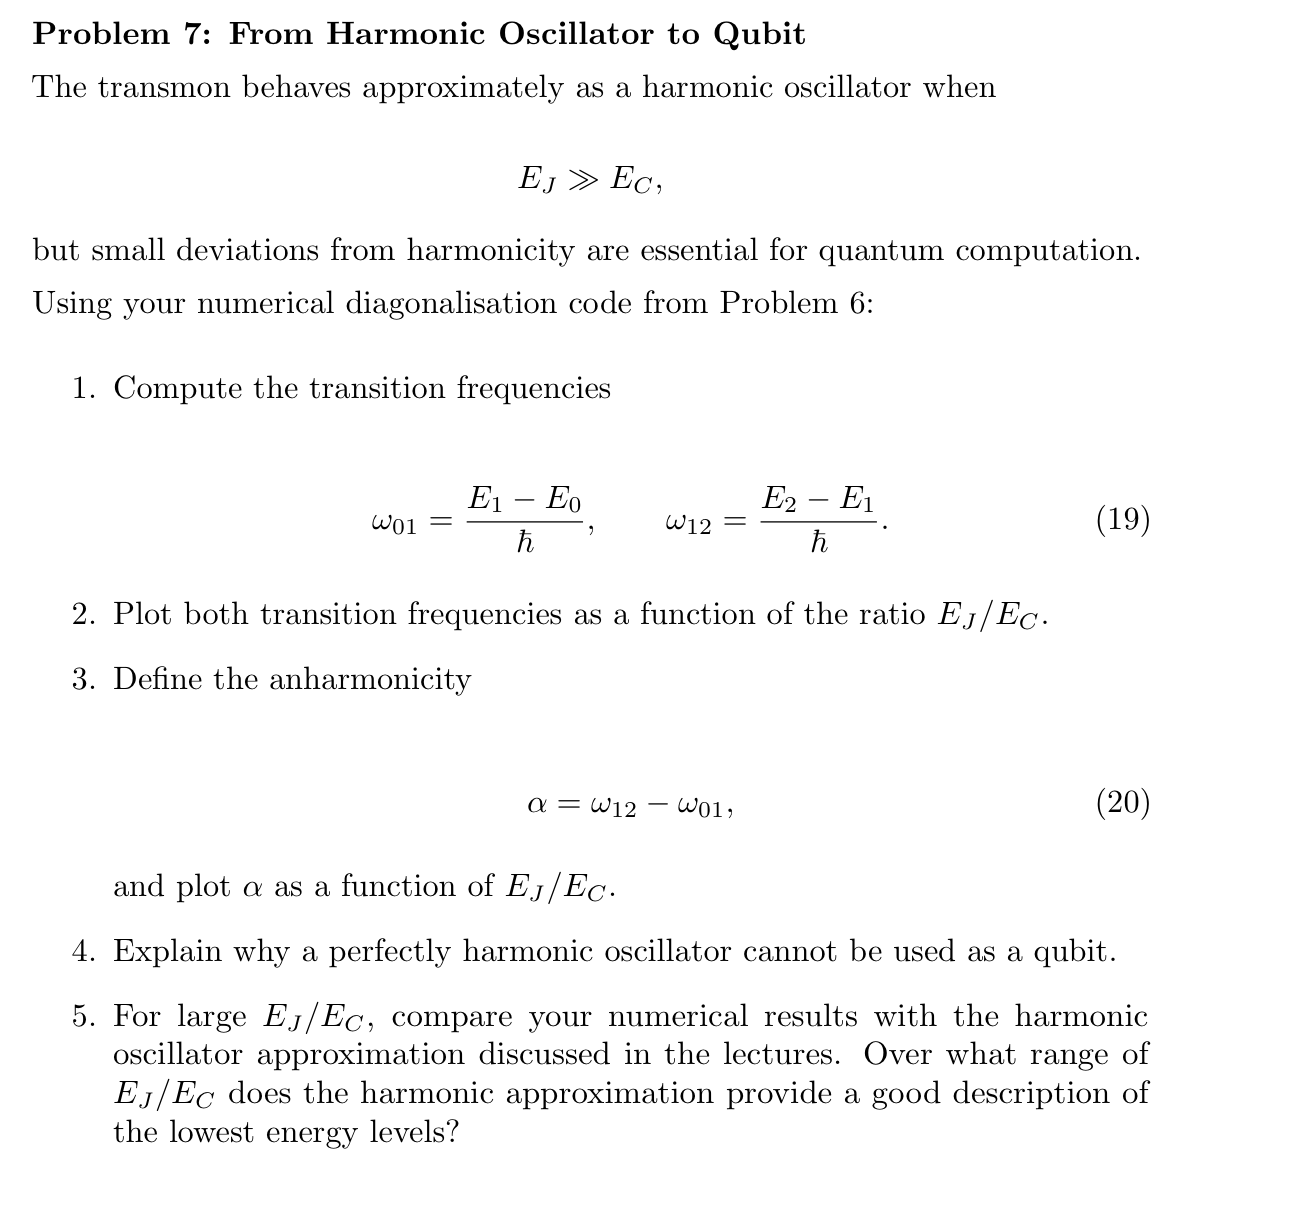

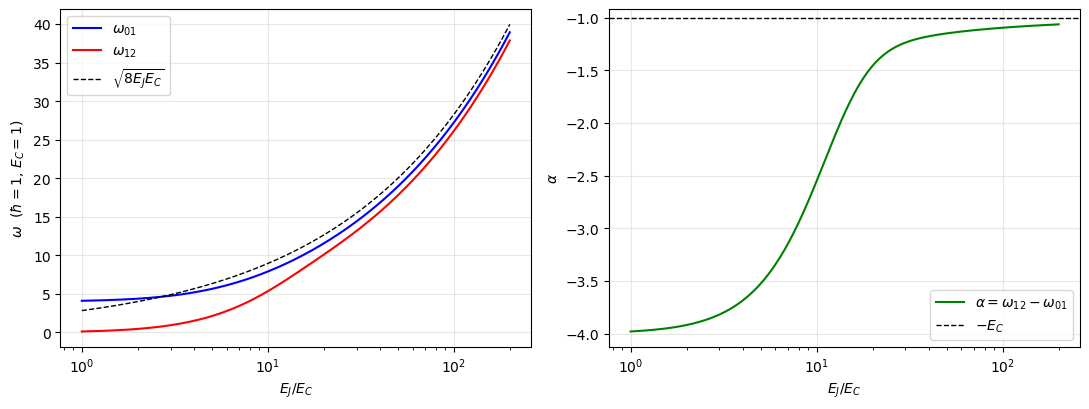

In [12]:
E_c = 1.0                              # fast skala -> entydig y-akse
ratios = np.logspace(0, 2.3, 300)      # E_J/E_C fra 1 til ~200

w01, w12, a = [], [], []
for r_val in ratios:
    H = H_1func(N, 4*E_c) + H_2func(L, -0.5*r_val*E_c)
    E = np.linalg.eigvalsh(H)
    w01.append(E[1]-E[0])
    w12.append(E[2]-E[1])
    a.append((E[2]-E[1]) - (E[1]-E[0]))

w01, w12 = np.array(w01), np.array(w12)

plt.figure(figsize=(11, 4.2))

plt.subplot(1, 2, 1)
plt.plot(ratios, w01, 'b-', label=r'$\omega_{01}$')
plt.plot(ratios, w12, 'r-', label=r'$\omega_{12}$')
plt.plot(ratios, np.sqrt(8*ratios)*E_c, 'k--', lw=1, label=r'$\sqrt{8E_JE_C}$')
plt.xscale('log')
plt.xlabel(r'$E_J/E_C$'); plt.ylabel(r'$\omega$  ($\hbar=1$, $E_C=1$)')
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(ratios, a, 'g-', label=r'$\alpha = \omega_{12}-\omega_{01}$')
plt.axhline(-E_c, color='k', ls='--', lw=1, label=r'$-E_C$')
plt.xscale('log')
plt.xlabel(r'$E_J/E_C$'); plt.ylabel(r'$\alpha$')
plt.legend(); plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
import numpy as np, matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt

N_max = 60
N = np.arange(-N_max, N_max+1); L = len(N)
def spec(E_c, E_j, k=5):
    H = (np.diag(4*E_c*N**2.0)
         - 0.5*E_j*(np.diag(np.ones(L-1),1)+np.diag(np.ones(L-1),-1)))
    return np.linalg.eigvalsh(H)[:k]

phi = np.linspace(-np.pi, np.pi, 600)
E_c = 1.0
cases = [(1.0, "$E_J/E_C = 1$\nlav brønd — intet parabelområde"),
         (50.0, "$E_J/E_C = 50$\ndyb brønd — bunden er en parabel")]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (E_j, title) in zip(axes, cases):
    V  = -E_j*np.cos(phi)
    Vh = -E_j + 0.5*E_j*phi**2          # parabel-approksimation
    ax.plot(phi, V, 'k-', lw=2, label=r'$-E_J\cos\varphi$')
    ax.plot(phi, Vh, 'r--', lw=1.5, label=r'$-E_J+\frac{E_J}{2}\varphi^2$')

    E = spec(E_c, E_j)
    sig = (2*E_c/E_j)**0.25
    for k, e in enumerate(E):
        ax.hlines(e, -np.pi, np.pi, color=f"C{k}", lw=1.6, alpha=.9)
        ax.text(np.pi*0.72, e, f"$|{k}\\rangle$", color=f"C{k}", fontsize=9, va='bottom')
    ax.axvspan(-sig, sig, color='orange', alpha=.15)
    ax.text(0, -E_j-0.06*E_j, r"$\sigma_\varphi=%.2f$" % sig, ha='center', fontsize=9)

    gaps = np.diff(E)
    ax.set_title(title + f"\nafstande: " + ", ".join(f"{g:.2f}" for g in gaps[:3]), fontsize=10)
    ax.set_xlabel(r'$\varphi$'); ax.set_ylim(-E_j*1.15, E[-1]+0.35*(E[-1]-E[0]))
    ax.set_xticks([-np.pi,0,np.pi]); ax.set_xticklabels([r'$-\pi$','0',r'$\pi$'])
    ax.legend(fontsize=8, loc='upper center'); ax.grid(alpha=.25)
axes[0].set_ylabel('energi')
fig.suptitle("Transmonen som pendul: dyb brønd $\\Rightarrow$ parabel $\\Rightarrow$ ækvidistante niveauer", fontsize=12)
fig.tight_layout(); fig.savefig('pendul_billede.png', dpi=160)

for E_j in [1, 10, 50, 200]:
    E = spec(1.0, E_j); g = np.diff(E)
    print(f"E_J/E_C={E_j:4g}  sigma_phi={(2/E_j)**0.25:.2f}  afstande: " + ", ".join(f"{x:6.3f}" for x in g[:3]))

E_J/E_C=   1  sigma_phi=1.19  afstande:  4.101,  0.122, 11.907
E_J/E_C=  10  sigma_phi=0.67  afstande:  7.900,  5.350,  9.199
E_J/E_C=  50  sigma_phi=0.45  afstande: 18.942, 17.793, 16.509
E_J/E_C= 200  sigma_phi=0.32  afstande: 38.973, 37.910, 36.796
